# Persistence and Shock Propagation

Controlled time-series experiments on stability, persistence, and the precision of averages. Parameters are fixed; all data are synthetic. [Executive summary](../EXECUTIVE_SUMMARY.md) | [Methods](../docs/methods.md) | [Research report](../docs/persistence_shock_propagation.pdf)

In [1]:
from pathlib import Path
import json
import os
import numpy as np
import pandas as pd
from IPython.display import Image, display
from shock_dynamics import ARSpecification, DynamicsAnalyzer
from shock_dynamics.pipeline import run_experiments

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'project3', Path.cwd().parent / 'project3']
PROJECT = next(p for p in candidates if (p / 'results/dynamics_summary.csv').is_file())
RESULTS = PROJECT / 'results'
if os.environ.get('RUN_SIMULATIONS') == '1':
    run_experiments(RESULTS, seed=20261115, replications=10000)
load = lambda name: json.loads((RESULTS / name).read_text())
summary = pd.read_csv(RESULTS / 'dynamics_summary.csv').set_index('experiment')
summary[['coefficients', 'intercept', 'innovation_variance', 'burn_in']]

,coefficients,intercept,innovation_variance,burn_in
experiment,,,,
ar1_persistent,0.9,0.0,1.0,500
ar1_mean_shift,0.9,0.5,1.0,500
ar3_stable,0.5;0.2;0.2,0.0,1.0,0
ar3_unstable,0.5;0.3;0.3,0.0,1.0,0
ar2_response,1.2;-0.3,0.0,1.0,500
ar2_boundary,1.5;-1.0,0.0,1.0,0


## Stability is a property of the model

The companion eigenvalues determine stability in the causal representation. A finite path is an illustration, not a stationarity test. Stationary moments and infinite response sums are deliberately absent for unstable and unit-circle models.

In [2]:
summary[['classification', 'spectral_radius', 'minimum_finite_root_modulus', 'stationary_mean', 'stationary_variance', 'long_run_sum']]

,classification,spectral_radius,minimum_finite_root_modulus,stationary_mean,stationary_variance,long_run_sum
experiment,,,,,,
ar1_persistent,stable,0.900000,1.111111,0.0,5.263158,10.0
ar1_mean_shift,stable,0.900000,1.111111,5.0,5.263158,10.0
ar3_stable,stable,0.939481,1.064418,0.0,3.492063,10.0
ar3_unstable,unstable,1.054380,0.948425,NaN,NaN,NaN
ar2_response,stable,0.844949,1.183503,0.0,7.428571,10.0
ar2_boundary,unit-circle boundary or numerically near boundary,1.000000,1.000000,NaN,NaN,NaN


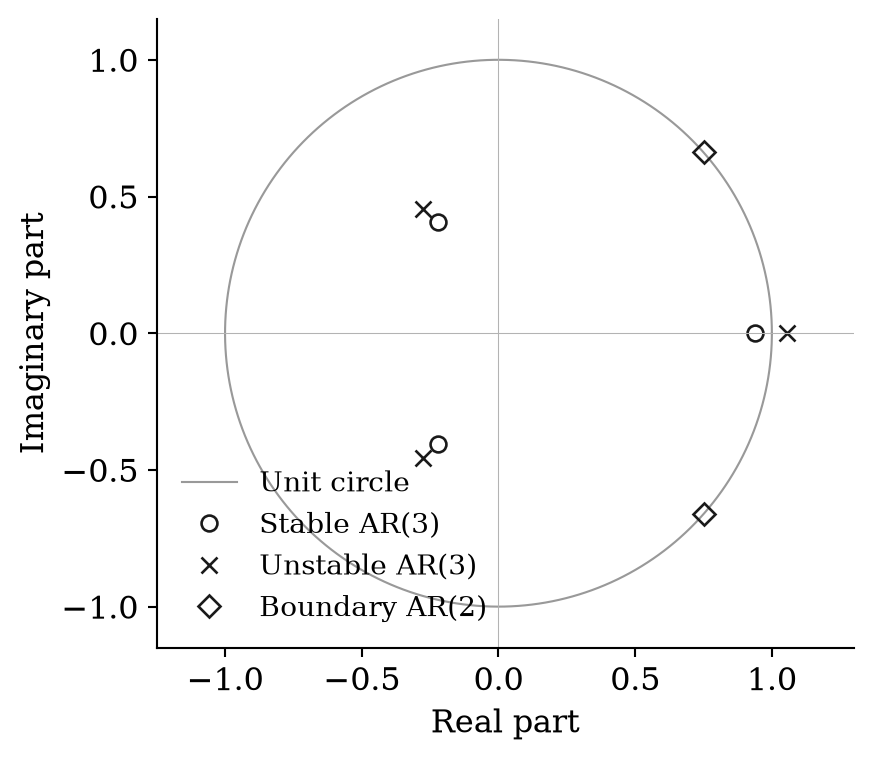

In [3]:
display(Image(filename=str(RESULTS / 'figures/companion_eigenvalues.png')))

## A controlled shock isolates transmission

The response at horizon zero is one. Matrix powers, coefficient recursion, and the difference between shocked and unshocked trajectories must agree. SciPy's linear filter supplies a fourth numerical control. All three stable zero-intercept models have an infinite cumulative response of ten, while their finite-horizon totals differ.

In [4]:
response = DynamicsAnalyzer(ARSpecification((1.2, -0.3))).impulse_response(100)
comparison = pd.DataFrame({'horizon': response.horizons, **response.methods, 'cumulative': response.cumulative})
display(comparison.iloc[:21])
print('Maximum three-method disagreement:', response.maximum_disagreement)
print('Analytical infinite sum:', DynamicsAnalyzer(ARSpecification((1.2, -0.3))).long_run_sum)

,horizon,recursion,matrix,shock,cumulative
0,0,1.000000,1.000000,1.000000,1.000000
1,1,1.200000,1.200000,1.200000,2.200000
2,2,1.140000,1.140000,1.140000,3.340000
3,3,1.008000,1.008000,1.008000,4.348000
4,4,0.867600,0.867600,0.867600,5.215600
5,5,0.738720,0.738720,0.738720,5.954320
6,6,0.626184,0.626184,0.626184,6.580504
7,7,0.529805,0.529805,0.529805,7.110309
8,8,0.447911,0.447911,0.447911,7.558219
9,9,0.378551,0.378551,0.378551,7.936771


Maximum three-method disagreement: 2.220446049250313e-16
Analytical infinite sum: 9.999999999999991


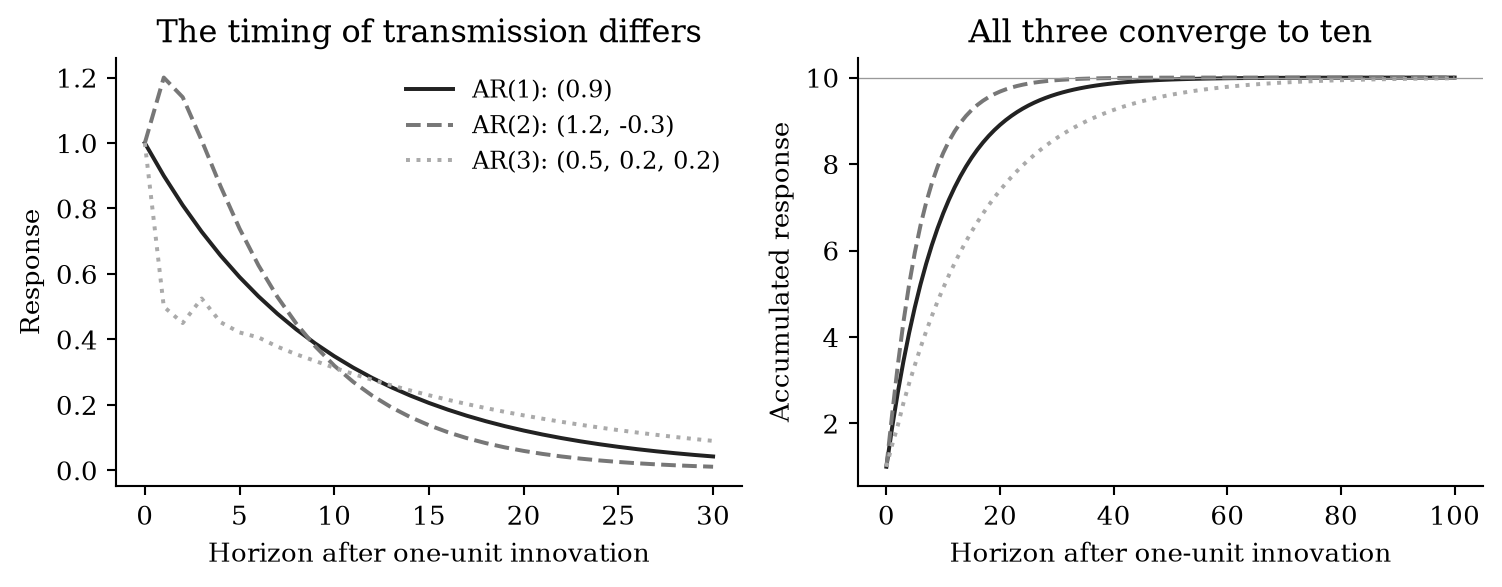

,cumulative_at_20,cumulative_at_100,remaining_sum_after_100
experiment,,,
ar1_persistent,8.905810,9.999761,2.390526e-04
ar2_response,9.676637,10.000000,4.530321e-07
ar3_stable,7.393773,9.982338,1.766199e-02


In [5]:
display(Image(filename=str(RESULTS / 'figures/shock_propagation.png')))
display(summary.loc[['ar1_persistent', 'ar2_response', 'ar3_stable'], ['cumulative_at_20', 'cumulative_at_100', 'remaining_sum_after_100']])

## The intercept changes the mean, not centered dynamics

Both AR(1) paths use exactly the same innovations and 500 burn-in periods. Their initial states differ by five, so changing the intercept from zero to 0.5 shifts every retained observation by five. The theoretical variance remains 1/(1-0.9²).

Maximum error relative to a five-unit shift: 1.7763568394002505e-15


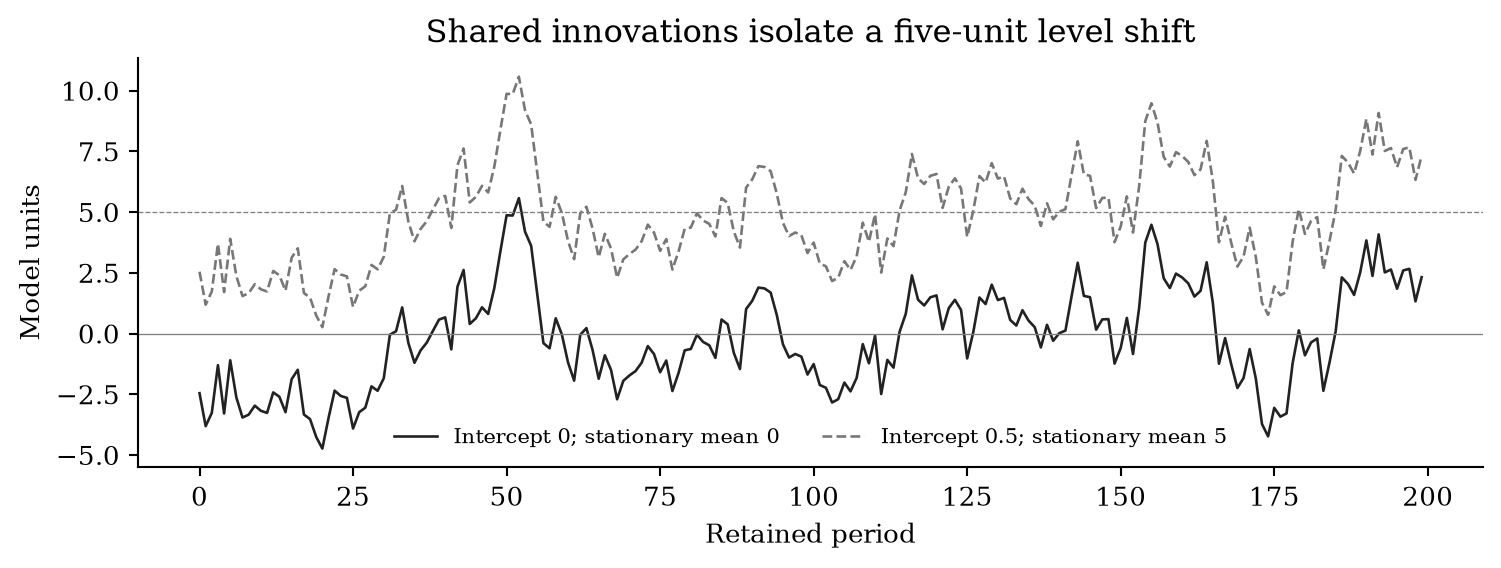

In [6]:
paths = pd.read_csv(RESULTS / 'simulation_paths.csv').pivot(index='period', columns='experiment', values='value')
print('Maximum error relative to a five-unit shift:', np.abs(paths.ar1_mean_shift - paths.ar1_persistent - 5).max())
display(Image(filename=str(RESULTS / 'figures/mean_adjustment.png')))

## Persistence reduces the information in an average

Each replication starts from the exact stationary Gaussian distribution. The finite-window mean variance uses the full autocovariance sum. The independence comparison keeps the same marginal variance but sets cross-time covariances to zero. Coverage refers to known-parameter repeated-sample intervals, not posterior probabilities.

In [7]:
precision = load('mean_precision.json')
keys = ['replications', 'length', 'exact_mean_variance', 'independence_mean_variance', 'variance_inflation_factor', 'effective_independent_observations', 'correlation_aware_coverage', 'independence_coverage', 'exact_independence_coverage']
pd.Series({key: precision[key] for key in keys}, name='Computed result')

replications                          10000.000000
length                                  200.000000
exact_mean_variance                       0.476316
independence_mean_variance                0.026316
variance_inflation_factor                18.100000
effective_independent_observations       11.049724
correlation_aware_coverage                0.950000
independence_coverage                     0.352700
exact_independence_coverage               0.354979
Name: Computed result, dtype: float64

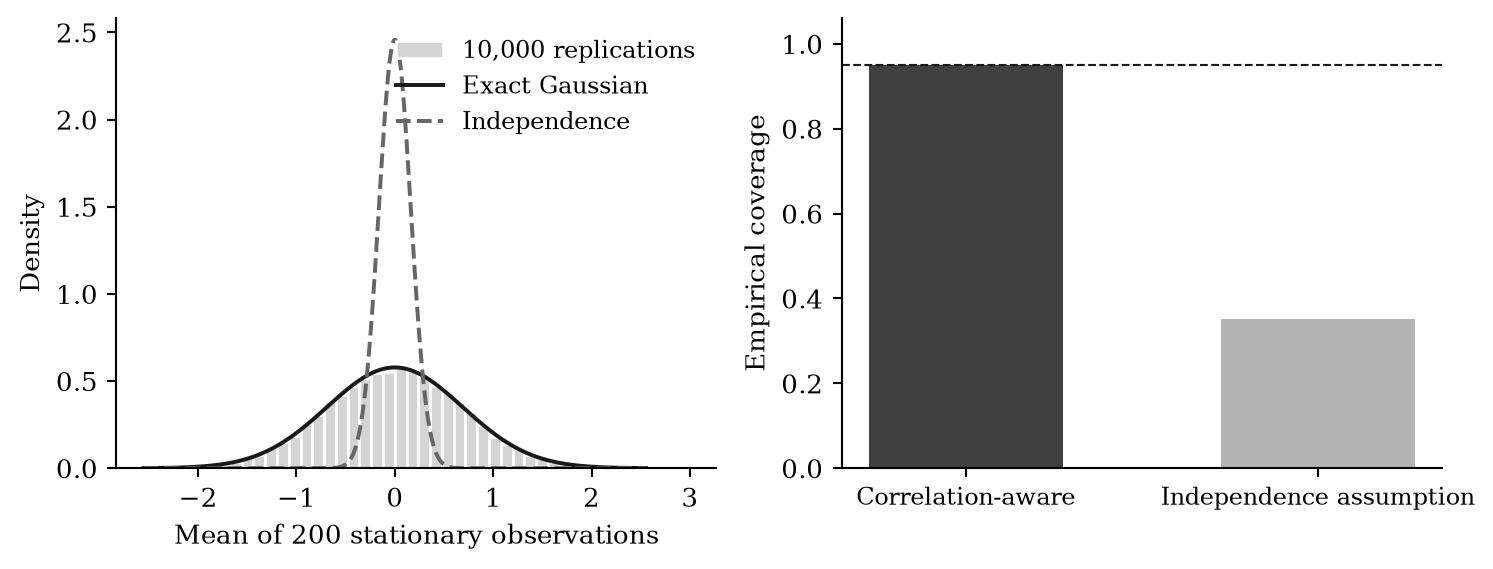

In [8]:
display(Image(filename=str(RESULTS / 'figures/mean_precision.png')))

## Shared innovations expose a stability change

The two AR(3) paths start from zero, use the same 200 innovations, and discard no observations. Their vertical scales differ. The unstable path has no stationary variance; its finite sample variance is not an estimate of a stationary population quantity.

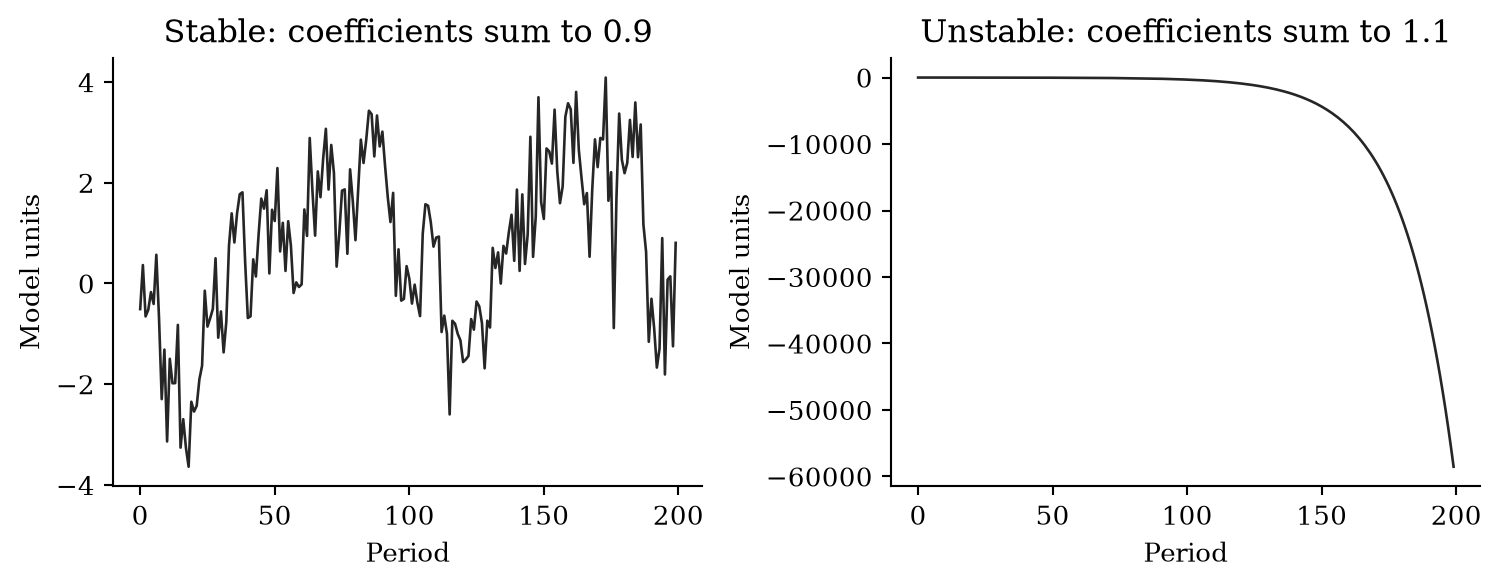

In [9]:
display(Image(filename=str(RESULTS / 'figures/stability_paths.png')))

## Stationarity and invertibility answer different questions

The finite MA(2) representation has constant second moments under white-noise innovations. Its polynomial roots are inside the unit circle, so that innovation representation is noninvertible. Autocovariances vanish beyond lag two.

covariance_stationary                            True
invertible                                      False
root_moduli                      [0.877058, 0.877058]
autocovariances_0_to_4    [4.94, 3.45, 1.3, 0.0, 0.0]
stationary_mean                                   0.0
stationary_variance                              4.94
dtype: object

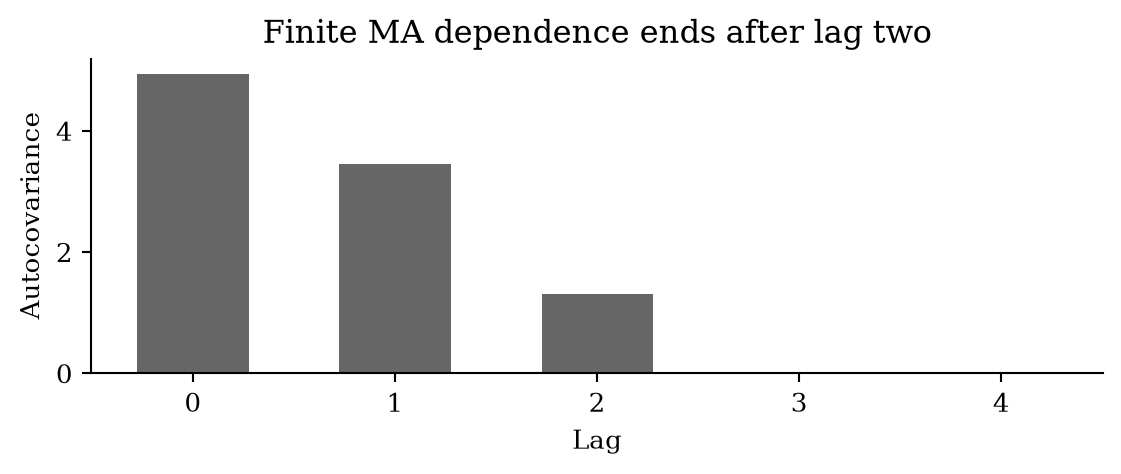

In [10]:
ma = load('ma_control.json')
display(pd.Series({k: v for k, v in ma.items() if k != 'specification'}))
display(Image(filename=str(RESULTS / 'figures/ma_autocovariance.png')))

## Numerical controls and reproducibility

The covariance solution must satisfy the Lyapunov equation and agree with a long squared-response sum. Roots, response conventions, variance scaling, initial-lag order, burn-in, and seeded reproduction have separate scientific tests. Checksums preserve the exact source and artifact identities for the recorded run.

In [11]:
checks = load('numerical_validation.json')
assert checks['all_deterministic_controls_pass']
display(pd.DataFrame({k: v for k, v in checks.items() if isinstance(v, dict)}).T)
display(load('run_metadata.json'))

,maximum_three_method_disagreement,scipy_filter_maximum_error,response_agreement_pass,lyapunov_maximum_residual,variance_vs_5001_response_terms_error,stationary_moment_controls_pass,maximum_path_shift_error
ar1_persistent,0.0,0.0,True,0.0,0.0,True,NaN
ar1_mean_shift,0.0,0.0,True,0.0,0.0,True,NaN
ar3_stable,0.0,0.0,True,0.0,0.0,True,NaN
ar3_unstable,0.0,0.0,True,NaN,NaN,NaN,NaN
ar2_response,0.0,0.0,True,0.0,0.0,True,NaN
ar2_boundary,0.0,0.0,True,NaN,NaN,NaN,NaN
mean_shift,NaN,NaN,NaN,NaN,NaN,NaN,0.0


{'python': '3.12.14',
 'platform': 'Darwin',
 'packages': {'numpy': '2.5.4',
  'scipy': '1.18.1',
  'pandas': '3.1.1',
  'matplotlib': '3.11.2'},
 'generator': 'numpy.random.default_rng / PCG64',
 'seed': 20261115,
 'data_source': 'Synthetic Gaussian innovations; parameters fixed by experiment design',
 'units': 'Generic model units and periods; no empirical frequency assigned',
 'root_boundary_tolerance': 1e-10,
 'response_comparison_rtol': 1e-11,
 'response_comparison_atol': 1e-11}

## Scope of the conclusions

The experiment quantifies model-implied mechanisms. It does not estimate macroeconomic coefficients, identify observed causal effects, or evaluate a live forecast. Periods have no imposed monthly or quarterly frequency. Generalizing requires a specified empirical dataset and an inference model.

To regenerate from the project directory: `shock-dynamics --output results --seed 20261115 --replications 10000`. The notebook normally reads committed artifacts; set `RUN_SIMULATIONS=1` only for an intentional rerun.